Dimensions de X :  (100, 2)
Dimensions de y :  (100, 1)


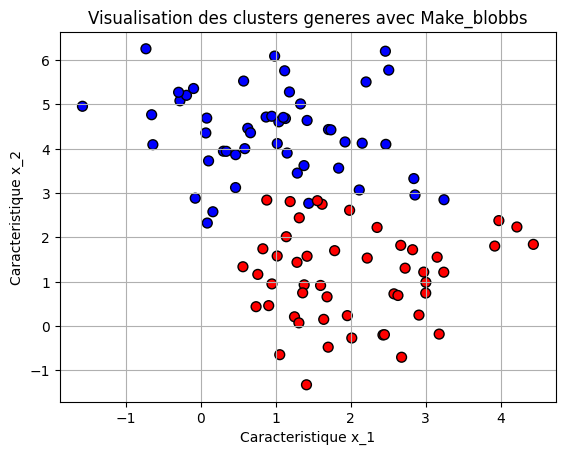

In [2]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

nb_obs=100
dim = 2
k=2
seed=0

X,y=make_blobs(n_samples=nb_obs , n_features=dim , centers=k , random_state=seed)

y=y.reshape((y.shape[0] , 1))

print('Dimensions de X : ' , X.shape)
print('Dimensions de y : ' , y.shape)

plt.scatter(X[:,0] , X[:,1], c=y , cmap="bwr" , edgecolors='k' , s=50)
plt.xlabel('Caracteristique x_1')
plt.ylabel('Caracteristique x_2')
plt.title("Visualisation des clusters generes avec Make_blobbs")
plt.grid(True)

In [3]:
xtrain, xtest, ytrain, ytest = train_test_split(
    torch.from_numpy(X).float(),
    torch.from_numpy(y).float(),
    test_size=0.2,
    random_state=42
)

In [15]:
model = nn.Linear(in_features=2 , out_features=1)

loss = nn.L1Loss()
optimazer = torch.optim.SGD(params=model.parameters() , lr=0.01)

In [16]:
epoch = 1000

for e in range(epoch):
    model.train()
    y_pred = model(xtrain)
    loss_fn = loss(y_pred , ytrain)
    optimazer.zero_grad()
    loss_fn.backward()
    optimazer.step()
    model.eval()
   
    if e % 10 == 0:
        with torch.no_grad():
            y_test_pred = model(xtest)
            loss_test = loss(y_test_pred, ytest)
            print(f"{e} : {loss_test}")
    

0 : 0.9371055364608765
10 : 0.5603829026222229
20 : 0.46535760164260864
30 : 0.421435683965683
40 : 0.37361282110214233
50 : 0.3358425498008728
60 : 0.326058954000473
70 : 0.3281317353248596
80 : 0.3251294493675232
90 : 0.3204496502876282
100 : 0.31522926688194275
110 : 0.3106876313686371
120 : 0.3072938323020935
130 : 0.3044585585594177
140 : 0.30131784081459045
150 : 0.2972027659416199
160 : 0.29291751980781555
170 : 0.28863227367401123
180 : 0.28356873989105225
190 : 0.27742817997932434
200 : 0.2709537446498871
210 : 0.26473960280418396
220 : 0.26027950644493103
230 : 0.25786346197128296
240 : 0.255545437335968
250 : 0.25370797514915466
260 : 0.2515464723110199
270 : 0.2493155300617218
280 : 0.2475915402173996
290 : 0.24577006697654724
300 : 0.24500498175621033
310 : 0.2437150478363037
320 : 0.2416401356458664
330 : 0.24043574929237366
340 : 0.2396678626537323
350 : 0.23821420967578888
360 : 0.23912644386291504
370 : 0.23843058943748474
380 : 0.2379399836063385
390 : 0.2377874851226

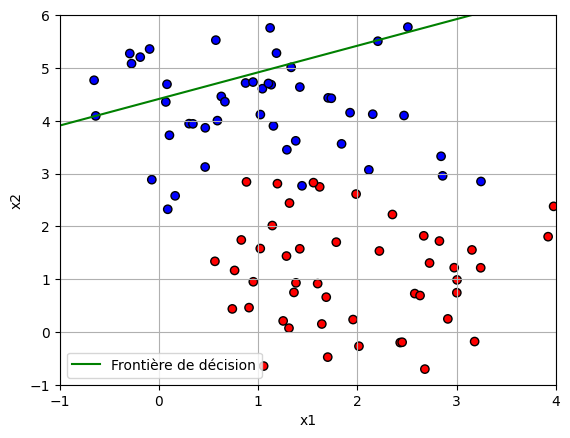

In [17]:
x1_vals = np.linspace(-2, 5, 100)

with torch.no_grad():
    weight = model.weight.cpu().numpy()[0]
    bias = model.bias.cpu().numpy()[0]


x2_vals = -(weight[0] * x1_vals + bias) / weight[1]
plt.scatter(X[:,0],X[:,1], c=y, cmap='bwr', edgecolors='k')
plt.plot(x1_vals, x2_vals, 'g-', label="Frontière de décision")
plt.xlim(-1, 4)
plt.ylim(-1, 6)
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()